### MoRong1

In [107]:
import pandas as pd
from sklearn.ensemble import RandomForestRegressor, RandomForestClassifier

# =========================
# LOAD DATA
# =========================
train_df = pd.read_csv("dataKPI.csv")
test_df = pd.read_csv("submission.csv")

# INPUT FEATURES
X_train = train_df[["Revenue", "COGS"]]
X_test = test_df[["Revenue", "COGS"]]

# =========================
# REGRESSION FEATURES
# =========================
regression_targets = [
    "total_quantity",
    "num_orders",
    "num_returns",
    "avg_payment"
]

for target in regression_targets:
    
    y_train = train_df[target]

    model = RandomForestRegressor(
        n_estimators=200,
        random_state=42
    )

    model.fit(X_train, y_train)

    test_df[target] = model.predict(X_test)

# =========================
# CLASSIFICATION FEATURE
# =========================
y_train = train_df["has_promotion"]

clf = RandomForestClassifier(
    n_estimators=200,
    random_state=42
)

clf.fit(X_train, y_train)

test_df["has_promotion"] = clf.predict(X_test)

# =========================
# RESULT
# =========================
print(test_df.head())

         Date       Revenue          COGS  total_quantity  num_orders  \
0  2023-01-01  1.700787e+06  1.499280e+06         273.775      55.100   
1  2023-01-02  1.245632e+06  1.098051e+06         194.760      43.995   
2  2023-01-03  1.201391e+06  1.059051e+06         224.060      45.580   
3  2023-01-04  1.176081e+06  1.036740e+06         220.300      45.445   
4  2023-01-05  1.360589e+06  1.199388e+06         241.160      50.590   

   num_returns   avg_payment  has_promotion  
0        3.535  29564.403405              1  
1        3.715  29905.607103              1  
2        6.875  23753.576746              1  
3        7.865  23575.764230              1  
4        4.600  23786.435526              1  


### MoRong2

In [109]:
import pandas as pd
import numpy as np

from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score,
    accuracy_score,
    classification_report
)

from sklearn.ensemble import (
    RandomForestRegressor,
    RandomForestClassifier
)

# =========================
# LOAD DATA
# =========================
df = pd.read_csv("dataKPI.csv")
submission = pd.read_csv("submission.csv")

# =========================
# INPUT FEATURES
# =========================
X = df[["Revenue", "COGS"]]

# =========================
# TARGETS
# =========================
regression_targets = [
    "total_quantity",
    "num_orders",
    "num_returns",
    "avg_payment"
]

classification_target = "has_promotion"

# =========================
# TRAIN / TEST SPLIT
# =========================
X_train, X_valid = train_test_split(
    X,
    test_size=0.2,
    random_state=42
)

# =====================================================
# REGRESSION MODELS
# =====================================================
print("=" * 50)
print("REGRESSION MODEL EVALUATION")
print("=" * 50)

for target in regression_targets:

    print(f"\nTARGET: {target}")

    # target split
    y = df[target]

    y_train = y.loc[X_train.index]
    y_valid = y.loc[X_valid.index]

    # model
    model = RandomForestRegressor(
        n_estimators=200,
        random_state=42
    )

    # train
    model.fit(X_train, y_train)

    # predict
    y_pred = model.predict(X_valid)

    # metrics
    mae = mean_absolute_error(y_valid, y_pred)
    rmse = np.sqrt(mean_squared_error(y_valid, y_pred))
    r2 = r2_score(y_valid, y_pred)

    print(f"MAE  : {mae:.4f}")
    print(f"RMSE : {rmse:.4f}")
    print(f"R2   : {r2:.4f}")

# =====================================================
# CLASSIFICATION MODEL
# =====================================================
print("\n" + "=" * 50)
print("CLASSIFICATION MODEL EVALUATION")
print("=" * 50)

# split target
y = df[classification_target]

y_train = y.loc[X_train.index]
y_valid = y.loc[X_valid.index]

# model
clf = RandomForestClassifier(
    n_estimators=200,
    random_state=42
)

# train
clf.fit(X_train, y_train)

# predict
y_pred = clf.predict(X_valid)

# metrics
acc = accuracy_score(y_valid, y_pred)

print(f"\nTARGET: {classification_target}")
print(f"Accuracy: {acc:.4f}")

print("\nClassification Report:")
print(classification_report(y_valid, y_pred))

# =====================================================
# TRAIN FULL DATA & PREDICT SUBMISSION
# =====================================================

X_full = df[["Revenue", "COGS"]]
X_submission = submission[["Revenue", "COGS"]]

# Regression predictions
for target in regression_targets:

    y_full = df[target]

    model = RandomForestRegressor(
        n_estimators=200,
        random_state=42
    )

    model.fit(X_full, y_full)

    submission[target] = model.predict(X_submission)

# Classification prediction
y_full = df[classification_target]

clf = RandomForestClassifier(
    n_estimators=200,
    random_state=42
)

clf.fit(X_full, y_full)

submission[classification_target] = clf.predict(X_submission)

# =====================================================
# SAVE RESULT
# =====================================================
# submission.to_csv("submission_final.csv", index=False)

print("\nDONE!")
print(submission.head())

REGRESSION MODEL EVALUATION

TARGET: total_quantity
MAE  : 121.4374
RMSE : 186.6594
R2   : 0.8966

TARGET: num_orders
MAE  : 21.4531
RMSE : 31.2896
R2   : 0.9254

TARGET: num_returns
MAE  : 4.3488
RMSE : 5.5735
R2   : 0.1498

TARGET: avg_payment
MAE  : 3656.8658
RMSE : 4829.9037
R2   : 0.4889

CLASSIFICATION MODEL EVALUATION

TARGET: has_promotion
Accuracy: 0.9164

Classification Report:
              precision    recall  f1-score   support

           0       0.89      0.96      0.93       379
           1       0.95      0.86      0.90       315

    accuracy                           0.92       694
   macro avg       0.92      0.91      0.91       694
weighted avg       0.92      0.92      0.92       694


DONE!
         Date       Revenue          COGS  total_quantity  num_orders  \
0  2023-01-01  1.700787e+06  1.499280e+06         273.775      55.100   
1  2023-01-02  1.245632e+06  1.098051e+06         194.760      43.995   
2  2023-01-03  1.201391e+06  1.059051e+06         224.06

### MoRong3

In [111]:
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt

from sklearn.model_selection import (
    train_test_split,
    cross_val_score,
    KFold
)

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)

from sklearn.ensemble import (
    RandomForestRegressor,
    RandomForestClassifier
)

In [112]:
# Load data
train_df = pd.read_csv("dataKPI.csv")
test_df = pd.read_csv("submission.csv")

In [113]:
train_df.head()

,Unnamed: 0,Date,Revenue,COGS,num_orders,total_payment,avg_payment,num_cod,num_credit,num_mobile,...,lag_366,lag_364,lag_363,rolling_mean_7,rolling_mean_30,rolling_std_7,rolling_mean_90,rolling_mean_365,rolling_max_7,rolling_min_7
0,0,2013-07-05,2494107.65,2432073.97,108,2045168.29,18936.743426,16,62,56,...,5123547.94,3054029.42,2667930.94,6.761811e+06,6.086493e+06,2.172762e+06,6.526941e+06,4.688697e+06,9546012.78,2521315.44
1,1,2013-07-06,2452372.43,2331799.51,94,2010945.41,21393.036277,12,61,34,...,2751773.45,2667930.94,2360851.90,6.220204e+06,5.940931e+06,2.715949e+06,6.513951e+06,4.687991e+06,9546012.78,2494107.65
2,2,2013-07-07,2958215.01,2950992.63,116,2425736.30,20911.519828,14,66,61,...,3054029.42,2360851.90,3548386.46,5.206827e+06,5.832914e+06,2.588606e+06,6.508702e+06,4.686342e+06,8038680.63,2452372.43
3,3,2013-07-08,2571901.18,2450996.77,115,2108958.96,18338.773565,18,62,48,...,2667930.94,3548386.46,5234938.62,4.576241e+06,5.803404e+06,2.509606e+06,6.489673e+06,4.687138e+06,8038680.63,2452372.43
4,4,2013-07-09,4624825.33,4592718.95,204,3792356.73,18589.983971,32,126,91,...,2360851.90,5234938.62,5582884.78,4.035103e+06,5.767569e+06,2.468974e+06,6.470547e+06,4.687716e+06,8038680.63,2452372.43


In [114]:
test_df.head()

,Date,Revenue,COGS
0,2023-01-01,1.700787e+06,1.499280e+06
1,2023-01-02,1.245632e+06,1.098051e+06
2,2023-01-03,1.201391e+06,1.059051e+06
3,2023-01-04,1.176081e+06,1.036740e+06
4,2023-01-05,1.360589e+06,1.199388e+06


In [115]:
print(train_df.shape)
print(test_df.shape)

(3467, 47)
(548, 3)


In [116]:
train_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3467 entries, 0 to 3466
Data columns (total 47 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   Unnamed: 0        3467 non-null   int64  
 1   Date              3467 non-null   object 
 2   Revenue           3467 non-null   float64
 3   COGS              3467 non-null   float64
 4   num_orders        3467 non-null   int64  
 5   total_payment     3467 non-null   float64
 6   avg_payment       3467 non-null   float64
 7   num_cod           3467 non-null   int64  
 8   num_credit        3467 non-null   int64  
 9   num_mobile        3467 non-null   int64  
 10  total_quantity    3467 non-null   int64  
 11  total_discount    3467 non-null   float64
 12  num_promo_orders  3467 non-null   int64  
 13  total_refund      3467 non-null   float64
 14  num_returns       3467 non-null   float64
 15  total_sessions    3467 non-null   float64
 16  total_visitors    3467 non-null   float64


In [117]:
train_df.isnull().sum()

Unnamed: 0          0
Date                0
Revenue             0
COGS                0
num_orders          0
total_payment       0
avg_payment         0
num_cod             0
num_credit          0
num_mobile          0
total_quantity      0
total_discount      0
num_promo_orders    0
total_refund        0
num_returns         0
total_sessions      0
total_visitors      0
total_pageviews     0
avg_bounce_rate     0
avg_rating          0
num_reviews         0
has_promotion       0
day_of_week         0
day_of_month        0
month               0
quarter             0
year                0
day_of_year         0
week_of_year        0
is_weekend          0
lag_1               0
lag_7               0
lag_14              0
lag_30              0
lag_365             0
lag_90              0
lag_180             0
lag_366             0
lag_364             0
lag_363             0
rolling_mean_7      0
rolling_mean_30     0
rolling_std_7       0
rolling_mean_90     0
rolling_mean_365    0
rolling_ma

In [118]:
train_df["Date"] = pd.to_datetime(train_df["Date"])
test_df["Date"] = pd.to_datetime(test_df["Date"])

In [119]:
for dataset in [train_df, test_df]:

    dataset["month"] = dataset["Date"].dt.month
    dataset["day"] = dataset["Date"].dt.day
    dataset["dayofweek"] = dataset["Date"].dt.dayofweek
    dataset["quarter"] = dataset["Date"].dt.quarter

    dataset["is_weekend"] = (
        dataset["dayofweek"] >= 5
    ).astype(int)

In [120]:
# for dataset in [train_df, test_df]:

#     dataset["profit"] = (
#         dataset["Revenue"] - dataset["COGS"]
#     )

#     dataset["margin"] = (
#         dataset["profit"] /
#         (dataset["Revenue"] + 1)
#     )

In [134]:
feature_cols = [
    "Revenue",
    "COGS",
    # "profit",
    # "margin",
    "month",
    "day",
    "dayofweek",
    "quarter",
    "is_weekend"
]

In [136]:
X = train_df[feature_cols]
X_test = test_df[feature_cols]

In [138]:
regression_targets = [
    "total_quantity",
    "num_orders",
    "num_returns",
    "avg_payment"
]

In [140]:
classification_target = "has_promotion"

In [142]:
X_train, X_valid = train_test_split(
    X,
    test_size=0.2,
    random_state=42
)

In [144]:
corr_df = train_df[
    feature_cols +
    regression_targets +
    [classification_target]
]

corr = corr_df.corr()

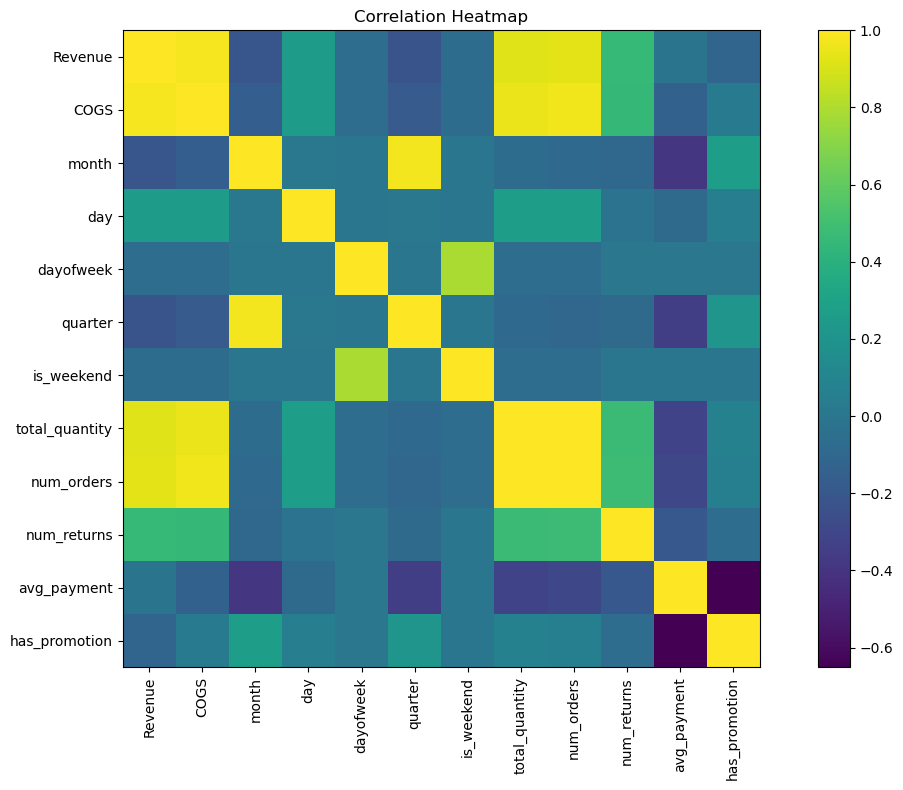

In [146]:
plt.figure(figsize=(12, 8))

plt.imshow(corr)

plt.colorbar()

plt.xticks(
    range(len(corr.columns)),
    corr.columns,
    rotation=90
)

plt.yticks(
    range(len(corr.columns)),
    corr.columns
)

plt.title("Correlation Heatmap")

plt.tight_layout()
plt.show()

In [147]:
regression_models = {}

In [148]:
for target in regression_targets:

    print("\n" + "=" * 50)
    print(f"TARGET : {target}")
    print("=" * 50)

    y = train_df[target]

    y_train = y.loc[X_train.index]
    y_valid = y.loc[X_valid.index]

    model = RandomForestRegressor(
        n_estimators=300,
        max_depth=10,
        min_samples_split=5,
        random_state=42,
        n_jobs=-1
    )

    model.fit(X_train, y_train)

    regression_models[target] = model

    y_pred = model.predict(X_valid)


TARGET : total_quantity

TARGET : num_orders

TARGET : num_returns

TARGET : avg_payment


In [149]:
mae = mean_absolute_error(y_valid, y_pred)

mse = mean_squared_error(y_valid, y_pred)

rmse = np.sqrt(mse)

r2 = r2_score(y_valid, y_pred)

mape = np.mean(
np.abs((y_valid - y_pred) / (y_valid + 1e-6))
) * 100

print(f"MAE   : {mae:.4f}")
print(f"MSE   : {mse:.4f}")
print(f"RMSE  : {rmse:.4f}")
print(f"R2    : {r2:.4f}")
print(f"MAPE  : {mape:.2f}%")

MAE   : 2979.1363
MSE   : 15528324.1872
RMSE  : 3940.5995
R2    : 0.6598
MAPE  : 11.95%


In [150]:
cv = KFold(
        n_splits=5,
        shuffle=True,
        random_state=42
    )

cv_scores = cross_val_score(
    model,
    X,
    y,
    scoring="r2",
    cv=cv,
    n_jobs=-1
)

print("\nCV Scores:")
print(cv_scores)

print(
    f"Average CV Score : {cv_scores.mean():.4f}"
)


CV Scores:
[0.65932313 0.68004302 0.66952204 0.67452424 0.61931385]
Average CV Score : 0.6605


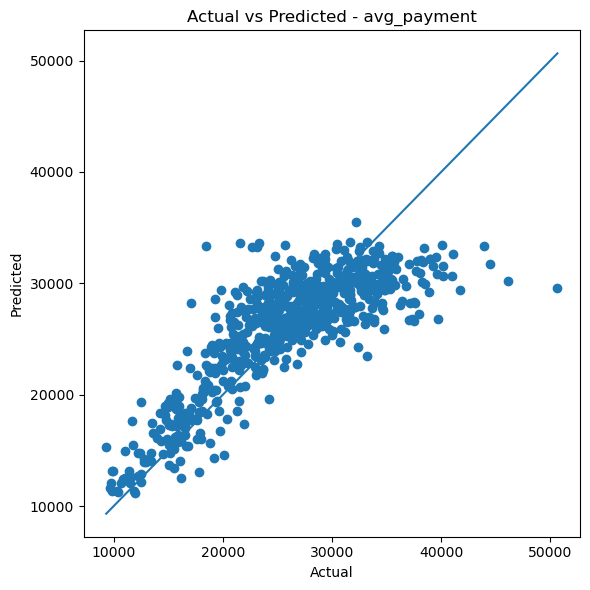

In [151]:
plt.figure(figsize=(6, 6))

plt.scatter(y_valid, y_pred)

plt.xlabel("Actual")
plt.ylabel("Predicted")

plt.title(
    f"Actual vs Predicted - {target}"
)

plt.plot(
    [y_valid.min(), y_valid.max()],
    [y_valid.min(), y_valid.max()]
)

plt.tight_layout()
plt.show()

In [152]:
importance_df = pd.DataFrame({
    "Feature": feature_cols,
    "Importance": model.feature_importances_
})

importance_df = importance_df.sort_values(
    by="Importance",
    ascending=True
)

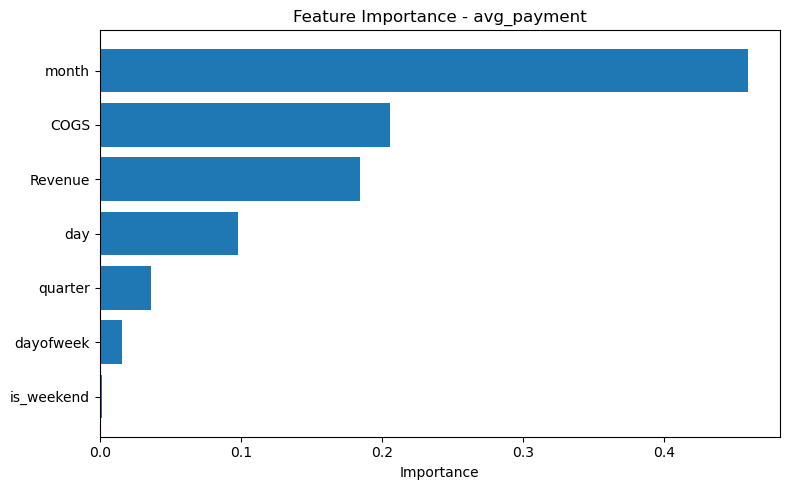

In [153]:
plt.figure(figsize=(8, 5))

plt.barh(
    importance_df["Feature"],
    importance_df["Importance"]
)

plt.xlabel("Importance")

plt.title(
    f"Feature Importance - {target}"
)

plt.tight_layout()
plt.show()

In [154]:
y = train_df[classification_target]

y_train = y.loc[X_train.index]
y_valid = y.loc[X_valid.index]

In [155]:
clf = RandomForestClassifier(
    n_estimators=300,
    max_depth=10,
    min_samples_split=5,
    random_state=42,
    n_jobs=-1
)

In [158]:
clf.fit(X_train, y_train)

,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",300
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.Note: This parameter is tree-specific.",'gini'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",10
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",5
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=""sqrt""The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to `""sqrt""`.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",'sqrt'
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow trees with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current node, ``N_t_L`` is the number of samples in theleft child, and ``N_t_R`` is the number of samples in the right child.``N``, ``N_t``, ``N_t_R`` and ``N_t_L`` all refer to the weighted sum,if ``sample_weight`` is passed... versionadded:: 0.19",0.0
,"bootstrap bootstrap: bool, default=TrueWhether bootstrap samples are used when building trees. If False, thewhole dataset is used to build each tree.",True
,"oob_score oob_score: bool or callable, default=FalseWhether to use out-of-bag samples to estimate the generalization score.By default, :func:`~sklearn.metrics.accuracy_score` is used.Provide a callable with signature `metric(y

In [159]:
y_pred = clf.predict(X_valid)

In [160]:
acc = accuracy_score(y_valid, y_pred)

precision = precision_score(
    y_valid,
    y_pred,
    zero_division=0
)

recall = recall_score(
    y_valid,
    y_pred,
    zero_division=0
)

f1 = f1_score(
    y_valid,
    y_pred,
    zero_division=0
)

In [161]:
print(f"Accuracy  : {acc:.4f}")
print(f"Precision : {precision:.4f}")
print(f"Recall    : {recall:.4f}")
print(f"F1 Score  : {f1:.4f}")

Accuracy  : 0.9467
Precision : 0.9427
Recall    : 0.9397
F1 Score  : 0.9412


In [162]:
print(
    classification_report(
        y_valid,
        y_pred
    )
)

              precision    recall  f1-score   support

           0       0.95      0.95      0.95       379
           1       0.94      0.94      0.94       315

    accuracy                           0.95       694
   macro avg       0.95      0.95      0.95       694
weighted avg       0.95      0.95      0.95       694



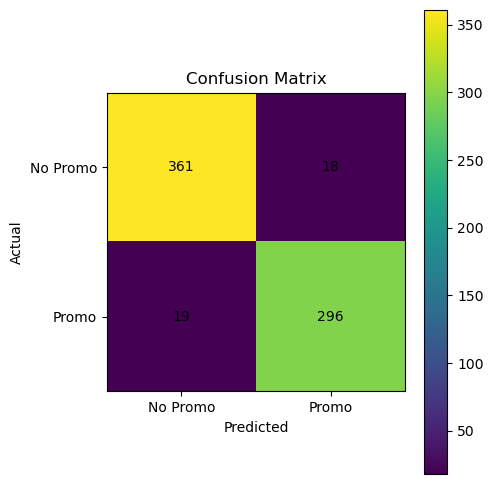

In [163]:
cm = confusion_matrix(
    y_valid,
    y_pred
)
plt.figure(figsize=(5, 5))

plt.imshow(cm)

plt.colorbar()

plt.xticks(
    [0, 1],
    ["No Promo", "Promo"]
)

plt.yticks(
    [0, 1],
    ["No Promo", "Promo"]
)

plt.xlabel("Predicted")
plt.ylabel("Actual")

plt.title("Confusion Matrix")

for i in range(cm.shape[0]):
    for j in range(cm.shape[1]):

        plt.text(
            j,
            i,
            cm[i, j],
            ha="center",
            va="center"
        )

plt.tight_layout()
plt.show()

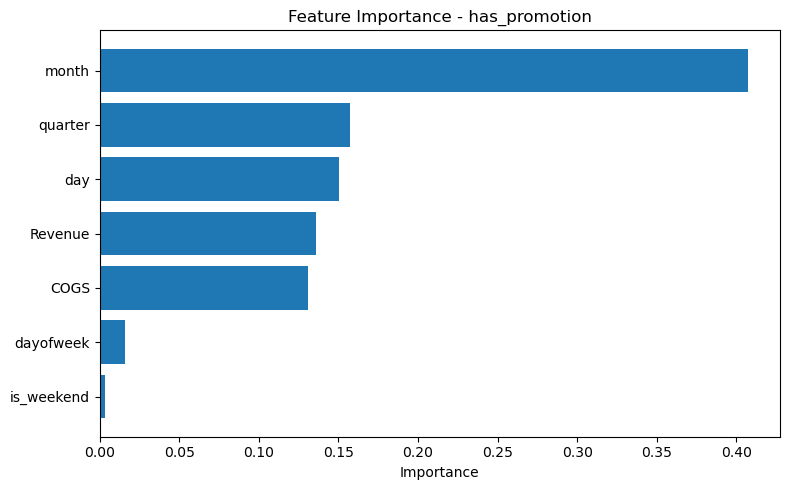

In [164]:
importance_df = pd.DataFrame({
    "Feature": feature_cols,
    "Importance": clf.feature_importances_
})

importance_df = importance_df.sort_values(
    by="Importance",
    ascending=True
)
plt.figure(figsize=(8, 5))

plt.barh(
    importance_df["Feature"],
    importance_df["Importance"]
)

plt.xlabel("Importance")

plt.title(
    "Feature Importance - has_promotion"
)

plt.tight_layout()
plt.show()

In [165]:
for target in regression_targets:

    y_full = train_df[target]

model = RandomForestRegressor(
    n_estimators=300,
    max_depth=10,
    min_samples_split=5,
    random_state=42,
    n_jobs=-1
)

model.fit(X, y_full)

test_df[target] = model.predict(X_test)

In [166]:
y_full = train_df[classification_target]

clf = RandomForestClassifier(
    n_estimators=300,
    max_depth=10,
    min_samples_split=5,
    random_state=42,
    n_jobs=-1
)

clf.fit(X, y_full)

# Predict

test_df[classification_target] = clf.predict(X_test)

In [167]:
test_df["total_quantity"] = (
    test_df["total_quantity"]
    .round()
    .astype(int)
)

test_df["num_orders"] = (
    test_df["num_orders"]
    .round()
    .astype(int)
)

test_df["num_returns"] = (
    test_df["num_returns"]
    .round()
    .astype(int)
)

test_df["has_promotion"] = (
    test_df["has_promotion"]
    .astype(int)
)

KeyError: 'total_quantity'

In [ ]:
test_df.head()